# 02 Components and parameters

A `Simulation` is a `Telescope`, a `Sensor`, a `Scene` and a `Coronagraph`. This notebook builds each one, looks at what it holds, assembles them by hand, and changes parameters with `update()` and `reset()`. It also covers the two choices that most affect the numbers: the photometric aperture and the filter curve.

> Requirements: an editable install (`pip install -e .`), as in notebook 01.

In [1]:
import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
from esc_etc import (Telescope, Sensor, get_scene, Coronagraph, Simulation,
                     FILTERS, use_lazuli_style)
use_lazuli_style()

## 1. Telescope

The collecting area is the Lyot-stop area, which is smaller than the 3 m primary. `resel` is the solid angle of a disk of diameter lambda/D at the design wavelength; it is the default photometric aperture.

In [2]:
t = Telescope.from_default()
print('primary diameter :', t.diameter_primary)
print('collecting area  :', t.surface)
print('f-number         :', round(t.f_num, 1))
print('resel            :', t.resel)

primary diameter : 3.0 m
collecting area  : 5.725552611167399 m2
f-number         : 36.7
resel            : 0.0014735970287905057 arcsec2


## 2. Sensor: detector and bandpass

The sensor holds the detector noise properties and the full non-coronagraphic throughput curve (`bandpass`). `num_psf_pixels` is the photometric aperture in detector pixels and `ee_fraction` is the fraction of an unaberrated Airy pattern that lands inside it. Both follow from `aperture`:

| `aperture` | what it is | pixels | encircled energy |
|---|---|---|---|
| `"resel"` (default) | disk of diameter lambda/D | 19.6 | 0.46 |
| `"optimal"` | disk of radius 0.7 lambda/D | 38 | 0.68 |
| `"box"` | square of side 2.44 lambda/D | 169 | 0.85 |
| `"matched"` | PSF-weighted sum; the matched-filter limit, not what a pipeline delivers | 70 (effective) | 1.00 |

The SNR barely moves between them for this scene because it is speckle limited, so the choice matters more for faint planets where read noise and background count. You can also override `encircled_energy` directly; it must be a fraction in (0, 1].

gain         : 0.9239970596457494 electron / ct
read noise   : 1.832077426554004 electron(1/2) / pix(1/2)
dark current : 0.0026523364364736 electron / (pix s)
well depth   : 15260.992347242305 electron / pix
aperture     : resel | 19.595181216030333 pix | EE 0.456


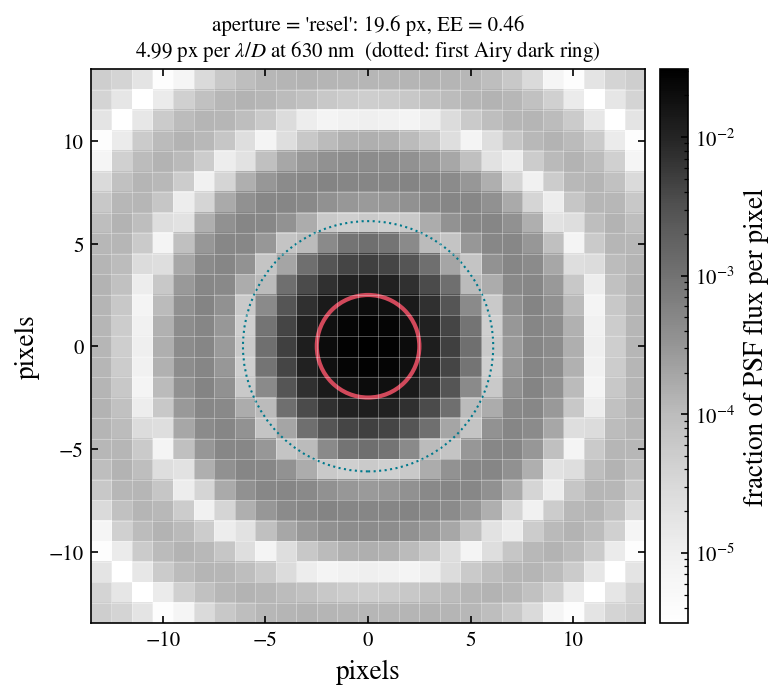

In [3]:
s = Sensor.from_default(t)
print('gain         :', s.gain)
print('read noise   :', s.read_noise)
print('dark current :', s.dark_current)
print('well depth   :', s.well_depth)
print('aperture     :', s.aperture, '|', s.num_psf_pixels, '| EE', round(s.ee_fraction, 3))
assert np.isclose(s.num_psf_pixels.value * s.plate_scale**2, t.resel.value)

fig, ax = s.plot_aperture()

## 3. Filters

`FILTERS` lists the ESC filter set. Passing `filter=` to `Simulation.from_default` uses that filter's measured curve as the whole bandpass and moves the telescope's design wavelength to match; `lifetime="eol"` (the default) or `"bol"` selects the end-of-life or beginning-of-life curve. The default is `DEFAULT_FILTER` (`F630N`, end of life). `filter=None` is the legacy option: the generic configuration chain, which is wider and a little more transmissive than any real filter.

When you build the components yourself, the telescope and the sensor must be built for the same filter. Mixing them raises a `ValueError`, because the pixel geometry would be computed at one wavelength and the throughput at another.

['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'F400N', 'F425N', 'F425W', 'F450N', 'F450W', 'F475N', 'F620N', 'F630N', 'F656N', 'F659W', 'F685N', 'F725.9N', 'R1', 'R2', 'R3', 'R4', 'R5', 'R6']


mismatch refused: filter='B1' (4000 Angstrom) does not match the telescope built for 6300 Angstrom; pass the same filter= to Telescope


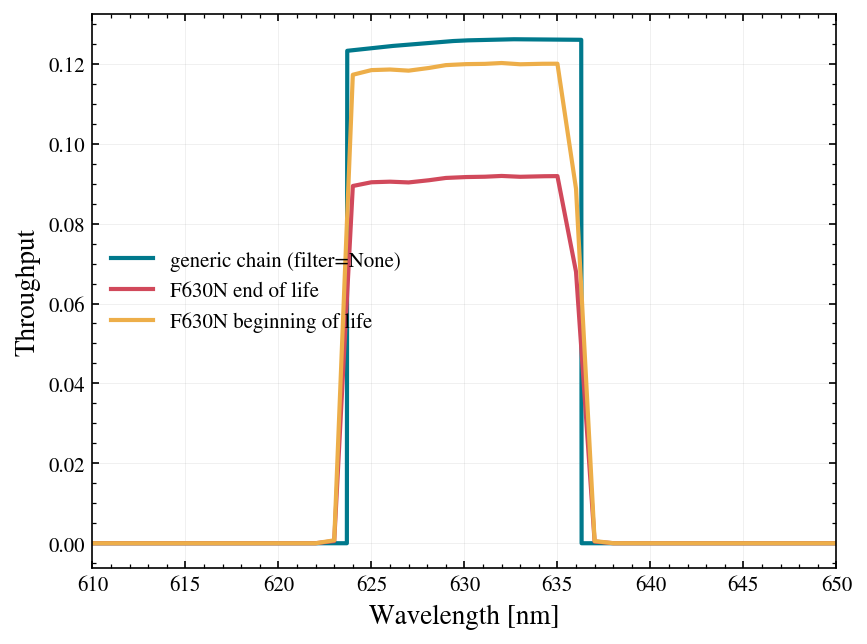

In [4]:
print(sorted(FILTERS))

fig, ax = plt.subplots()
Simulation.from_default(filter=None).plot_bandpass(ax=ax, label='generic chain (filter=None)')
Simulation.from_default(filter='F630N', lifetime='eol').plot_bandpass(ax=ax, label='F630N end of life')
Simulation.from_default(filter='F630N', lifetime='bol').plot_bandpass(ax=ax, label='F630N beginning of life')
ax.set_xlim(610, 650);

try:
    Sensor.from_default(Telescope.from_default(), filter='B1')
except ValueError as err:
    print('mismatch refused:', err)

## 4. Scene and coronagraph

`get_scene` builds the star, planet, zodi and exozodi elements. The star and planet magnitudes are Vega magnitudes in the ESC band by default; `hoststar_band=` and `mag_system=` change that. The coronagraph carries the raw dark-hole contrast, the post-processing gain and the planet separation.

star mag    : -0.353 vega
planet dmag : 20
contrast    : 1e-08 | ppgain 10 | separation 0.2 arcsec


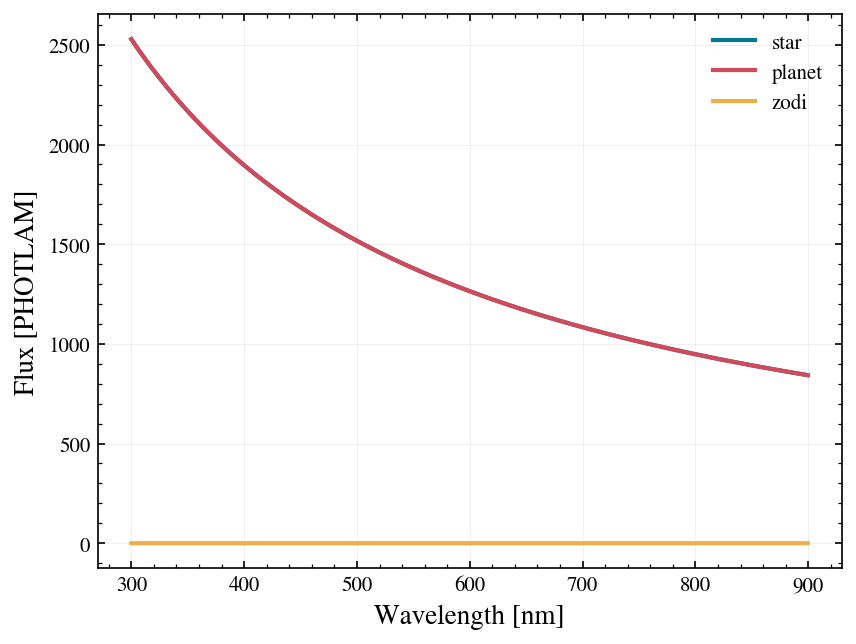

In [5]:
scene = get_scene(t, hoststarmag=-0.353, planetdeltamag=20, bg_flux=22.5, exobg_flux=21)
c = Coronagraph.from_default(t, raw_dh_contrast=1e-8, ppgain=10, separation=0.2)
print('star mag    :', scene.star.mag, scene.star.mag_system)
print('planet dmag :', scene.planet.deltamag)
print('contrast    :', c.raw_dh_contrast, '| ppgain', c.ppgain, '| separation', c.separation, 'arcsec')

fig, ax = scene.plot_spectra()

## 5. Assemble by hand

`from_components` gives the same object `from_default` would have built.

In [6]:
sim = Simulation.from_components(t, s, scene, c)
base = sim.get_snr(3600, 100)['snr']
print('SNR:', round(base, 3))
assert abs(base - Simulation.from_default().get_snr(3600, 100)['snr']) < 1e-9

SNR: 9.747


## 6. Change parameters

`update()` changes a parameter in place and the next calculation sees it. From the simulation, nested parameters are addressed with double underscores, so `sim.update(coronagraph__ppgain=100)` is the same as `sim.coronagraph.update(ppgain=100)`. An invalid value is refused and leaves the object unchanged. `sim.reset()` puts every component back to its initial state.

Two changes below, one at a time. A fainter host means a fainter planet, because the planet is defined relative to the host, so the SNR drops and the curve is no longer near its plateau. Raising `ppgain` then lifts the plateau from 10 to 100 and the SNR climbs back most of the way, but not above the default scene's: the fainter planet is photon-limited rather than speckle-limited, so a higher plateau helps less than it would for the bright host.

In [7]:
sim.update(scene__star__mag=2.0)
faint = sim.get_snr(3600, 100)['snr']
print('host 2.35 mag fainter        :', round(faint, 3))
sim.update(coronagraph__ppgain=100)
faint_pp = sim.get_snr(3600, 100)['snr']
print('... and post-processing gain 100:', round(faint_pp, 3))
assert faint < faint_pp < base

try:
    sim.update(sensor__encircled_energy=1.7)
except ValueError as err:
    print('refused:', err)

sim.reset()
print('after reset:', round(sim.get_snr(3600, 100)['snr'], 3))
assert abs(sim.get_snr(3600, 100)['snr'] - base) < 1e-9

host 2.35 mag fainter        : 6.731
... and post-processing gain 100: 9.064
refused: encircled_energy must be in (0, 1], got 1.7
after reset: 9.747


Notebook 03 looks at what the three coronagraph parameters do to the SNR curve.